## Combine Tony Grove
Load and combine Tony Grove data into a netCDF. All times should be UTC.

Data to combine:
- LWdown (W/m2)
- SWdown
- Psurf (Pa)
- Qair (kg/kg) Specific humidity
- Rainf (kg/m2/s) Rainfall rate
- Snowf (kg/m2/s)
- Tair (K)
- Wind (m/s)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from gdriver.gdriver import getCSVtoPandas, get_credentials

Site Information

In [2]:
# Used by the model for various purposes
latitude = 41.885493
longitude = -111.568767
reference_height = 10 #?
canopy_height = 10  #?

In [2]:
# Load Google Drive credentials
credentials = get_credentials()

### Precipitation
This data comes directly from the SNOTEL. I downloaded each year from SNOTEL as a CSV and stored it in the TonyGroveSnotel folder.

In [6]:
snotel_precip = pd.DataFrame()
for i in range(2014,2023):
    yearly_precip = getCSVtoPandas(f'TonyGroveSnotel/1113_17_YEAR={i}.csv', credentials, skiprows=6)
    snotel_precip = pd.concat([snotel_precip, yearly_precip])

snotel_precip.head()

Download 100.
Download 100.
Download 100.
Download 100.
Download 100.
Download 100.
Download 100.
Download 100.
Download 100.


,Site Id,Date,Time,PREC.I-1 (in),Unnamed: 4
0,1113,2014-01-01,00:00,3.8,NaN
1,1113,2014-01-01,01:00,3.7,NaN
2,1113,2014-01-01,02:00,3.7,NaN
3,1113,2014-01-01,03:00,3.7,NaN
4,1113,2014-01-01,04:00,3.7,NaN


In [7]:
# Drop Site Id and Unnamed: 4 columns
snotel_precip = snotel_precip.drop(columns=['Site Id', 'Unnamed: 4'])

# Convert Date and Time to datetime
snotel_precip['Date and Time'] = snotel_precip['Date'] + ' ' + snotel_precip['Time']
snotel_precip.index = pd.to_datetime(snotel_precip['Date and Time'])


In [8]:
# Drop Date and Time columns
snotel_precip = snotel_precip.drop(columns=['Date', 'Time', 'Date and Time'])

In [9]:
# Replace -99.9 with NaN
snotel_precip = snotel_precip.replace(-99.9, np.nan)

<Axes: xlabel='Date and Time'>

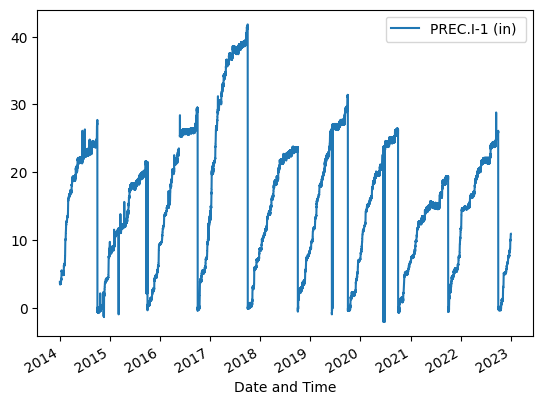

In [10]:
# Initial plot of data
snotel_precip.plot()

#### Temperature
Tony grove has two different sensors, the ST110 and the EE08. The EE08 isn't installed until 2017. I remember there were some issues with the ST110 being exposed to light from the bottom of the shield, and the EE08 was supposed to have a better reputation. I think even the HC2S3 had a temperature sensor. For now I will just start with the ST110.

In [ ]:
# Get the ST110 data
Tair = getCSVtoPandas('TonyGrove/LR_TG_C_AirTemp_ST110_Avg_SourceID_1_QC_1.csv',credentials,skiprows=56)

In [8]:
# Change index to DateTimeUTC
Tair['DateTimeUTC'] = pd.to_datetime(Tair['DateTimeUTC'])
Tair = Tair.set_index('DateTimeUTC')

# Convert -9999 to NaN
Tair = Tair.replace(-9999, np.nan)

In [ ]:
Tair.head()

In [10]:
# Convert to Kelvin
Tair['Tair'] = Tair['AirTemp_ST110_Avg'] + 273.15

In [ ]:
Tair[Tair.index.duplicated()]

#### Wind
Wind is already in m/s, but will eventually need to be standardized to a certain height. Ignore that for now...

In [ ]:
Wind = getCSVtoPandas('TonyGrove/LR_TG_C_WindSp_Avg_SourceID_1_QC_1.csv',credentials,skiprows=57)

# Change index to DateTimeUTC
Wind['DateTimeUTC'] = pd.to_datetime(Wind['DateTimeUTC'])
Wind = Wind.set_index('DateTimeUTC')

# Convert -9999 to NaN
Wind = Wind.replace(-9999, np.nan)

In [ ]:
Wind.head()

In [13]:
# Adjust for height
# TODO: Implement this

### Combine into NetCDF

In [14]:
import xarray as xr

In [17]:
# Convert dataframes to xarray dataarrays
Tair_da = xr.DataArray(Tair['Tair'], coords=[Tair.index], dims=['time'])
Wind_da = xr.DataArray(Wind['WindSp_Avg'], coords=[Wind.index], dims=['time'])

In [ ]:
# Combine the dataarrays into a dataset
ds = xr.Dataset({'Tair': Tair_da, 'Wind': Wind_da})

# Include latitude and longitude as coordinates
ds.coords['latitude'] = latitude
ds.coords['longitude'] = longitude

# Include reference height and canopy height as attributes
# TODO: Implement this
